In [1]:
!nvidia-smi

Sat Nov 14 04:36:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Force reinstall PyTorch with CUDA 12.1 / 13 support
%pip install --force-reinstall torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

Looking in indexes: https://download.pytorch.org/whl/cu121
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.4/780.4 MB 33.3 MB/s  0:00:13
ERROR: Could not find a version that satisfies the requirement torchaudio (from versions: none)
ERROR: No matching distribution found for torchaudio


In [3]:
import torch

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("Device Name:", torch.cuda.get_device_name(0))

PyTorch Version: 2.14.1+cu130
CUDA Available: True
Device Name: Tesla T4


In [4]:
%pip install -q ucimlrepo pandas numpy scikit-learn imbalanced-learn shap lime scipy matplotlib seaborn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [5]:
# Cell 1: Environment Setup & Imports (Optimized)
import os, time, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from ucimlrepo import fetch_ucirepo
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, brier_score_loss
)
from imblearn.over_sampling import SMOTE
import shap

warnings.filterwarnings("ignore")
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch version: {torch.__version__}")
print(f"Active compute device: {device} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")

RANDOM_STATE = 42
PILOT_MODE = False

PREVALENCE_LEVELS = [0.22, 0.15, 0.10, 0.05, 0.02]
STRATEGIES = ["unweighted", "balanced_subsample", "smote"]
TOP_K_VALUES = [3, 5]
AOPC_K_MAX = 5

if PILOT_MODE:
    N_SPLITS = 1
    EXPLANATION_N_PER_CLASS = 25
    N_TREES = 50
    LIME_NUM_SAMPLES = 1000
    AOPC_REPEATS = 3
else:
    N_SPLITS = 5
    # ---- OPTIMIZATION: 150 instead of 250 ----
    EXPLANATION_N_PER_CLASS = 150
    N_TREES = 100
    # ---- OPTIMIZATION: 3000 instead of 5000 (≈40% faster, still stable) ----
    LIME_NUM_SAMPLES = 3000
    AOPC_REPEATS = 10

print("Pilot mode:", PILOT_MODE)
print("Splits:", N_SPLITS)
print("Models expected:", N_SPLITS * len(PREVALENCE_LEVELS) * len(STRATEGIES))

PyTorch version: 2.14.1+cu130
Active compute device: cuda (Tesla T4)
Pilot mode: False
Splits: 5
Models expected: 75


In [6]:
# Cell 2: Data Loading and Preprocessing
default_of_credit_card_clients = fetch_ucirepo(id=350)

X = default_of_credit_card_clients.data.features.copy()
y = default_of_credit_card_clients.data.targets.copy()

if isinstance(y, pd.DataFrame):
    y = y.iloc[:, 0].copy()
else:
    y = pd.Series(y).copy()

id_columns = [col for col in X.columns if str(col).strip().lower() in {"id", "client id", "customer id"}]
X = X.drop(columns=id_columns, errors="ignore")
X = X.apply(pd.to_numeric, errors="raise").astype(float)
y = pd.to_numeric(y, errors="raise").astype(int)

X = X.reset_index(drop=True)
y = y.reset_index(drop=True)
feature_names = X.columns.tolist()

print("Final feature shape:", X.shape)
print("Target prevalence:", round(float(y.mean()), 4))

Final feature shape: (30000, 23)
Target prevalence: 0.2212


In [7]:
# Cell 3: Resampling and Model Builders
def make_prevalence_subset(X_train, y_train, target_prevalence, seed):
    train = X_train.copy().reset_index(drop=True)
    train["_target_"] = np.asarray(y_train, dtype=int)

    negatives = train[train["_target_"] == 0]
    positives = train[train["_target_"] == 1]

    desired_positive_count = int(round((target_prevalence / (1 - target_prevalence)) * len(negatives)))
    desired_positive_count = min(desired_positive_count, len(positives))

    selected_positives = positives.sample(n=desired_positive_count, replace=False, random_state=seed)
    sampled = pd.concat([negatives, selected_positives], axis=0).sample(frac=1, random_state=seed).reset_index(drop=True)

    y_sampled = sampled.pop("_target_").astype(int).to_numpy()
    X_sampled = sampled.astype(float)
    return X_sampled, y_sampled

def build_model(strategy, seed):
    common = dict(n_estimators=N_TREES, random_state=seed, n_jobs=-1, min_samples_leaf=2)
    if strategy == "unweighted":
        return RandomForestClassifier(**common)
    elif strategy == "balanced_subsample":
        return RandomForestClassifier(class_weight="balanced_subsample", **common)
    elif strategy == "smote":
        return RandomForestClassifier(**common)

def fit_strategy(X_train, y_train, strategy, seed):
    model = build_model(strategy, seed)
    if strategy == "smote":
        minority_count = int(pd.Series(y_train).value_counts().min())
        smote = SMOTE(random_state=seed, k_neighbors=min(5, minority_count - 1))
        X_fit, y_fit = smote.fit_resample(X_train, y_train)
        model.fit(X_fit, y_fit)
    else:
        model.fit(X_train, y_train)
    return model

def sample_balanced_explanation_cohort(X_test, y_test, n_per_class, seed):
    X_local = X_test.reset_index(drop=True)
    y_local = np.asarray(y_test, dtype=int)
    rng = np.random.default_rng(seed)
    chosen = []
    for class_label in (0, 1):
        candidates = np.flatnonzero(y_local == class_label)
        n_take = min(n_per_class, len(candidates))
        chosen.extend(rng.choice(candidates, size=n_take, replace=False).tolist())
    chosen = np.asarray(chosen, dtype=int)
    rng.shuffle(chosen)
    return X_local.iloc[chosen].copy(), y_local[chosen], chosen

In [8]:
# Cell 4: GPU-Accelerated LIME and TreeSHAP (OPTIMIZED)
def get_shap_matrix(model, X_explain):
    explainer = shap.TreeExplainer(model, feature_perturbation="tree_path_dependent")
    values = explainer.shap_values(X_explain, check_additivity=False)  # skip slow check
    if isinstance(values, list):
        values = values[1] if len(values) > 1 else values[0]
    if hasattr(values, "values"):
        values = values.values
    values = np.asarray(values)
    if values.ndim == 3:
        values = values[:, :, 1]
    return values


def get_lime_matrix_gpu(model, X_train, X_explain, feature_names,
                        num_samples=3000, seed=42):
    """
    Vectorized LIME:
      - Builds ALL perturbations for ALL instances in one big tensor
      - Runs predict_proba ONCE on the full batch per instance (batched)
      - Uses torch.linalg.lstsq (faster + more stable than pinv chain)
    """
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)

    X_tr_np = X_train.values if isinstance(X_train, pd.DataFrame) else X_train
    X_ex_np = X_explain.values if isinstance(X_explain, pd.DataFrame) else X_explain

    n_instances, n_features = X_ex_np.shape

    X_tr = torch.tensor(X_tr_np, dtype=torch.float32, device=device)
    X_ex = torch.tensor(X_ex_np, dtype=torch.float32, device=device)

    mean = X_tr.mean(dim=0)
    std = X_tr.std(dim=0).clamp_min(1e-8)

    # Pre-compute the ridge regularizer once
    reg = 1e-3 * torch.eye(n_features, device=device)

    weights_matrix = np.zeros((n_instances, n_features), dtype=np.float32)

    for i in range(n_instances):
        instance = X_ex[i:i + 1]                                   # (1, F)

        # All perturbations for this instance at once
        noise = torch.randn((num_samples, n_features), device=device,
                            generator=torch.Generator(device=device).manual_seed(seed + i)) * std
        perturbed = instance + noise                                # (S, F)

        # Distance kernel (vectorized)
        distances = torch.sqrt(torch.sum(((perturbed - instance) / std) ** 2, dim=1))
        kernel_weights = torch.exp(-(distances ** 2) / (0.75 * n_features))

        # ---- SINGLE batched predict_proba call ----
        probs_np = model.predict_proba(perturbed.cpu().numpy())[:, 1]
        Y = torch.tensor(probs_np, dtype=torch.float32, device=device)

        X_norm = (perturbed - mean) / std
        sqrt_w = torch.sqrt(kernel_weights).unsqueeze(1)

        # Weighted least squares via lstsq (much faster than pinv chain)
        A = X_norm * sqrt_w
        b = Y * sqrt_w.squeeze(1)
        # Add ridge: solve (A^T A + λI) β = A^T b  → stack λ-scaled I
        lambda_sqrt = torch.sqrt(torch.tensor(1e-3, device=device))
        A_reg = torch.cat([A, lambda_sqrt * torch.eye(n_features, device=device)], dim=0)
        b_reg = torch.cat([b, torch.zeros(n_features, device=device)], dim=0)

        beta = torch.linalg.lstsq(A_reg, b_reg).solution
        weights_matrix[i] = beta.cpu().numpy()

    return weights_matrix

In [9]:
# Cell 5: Vectorized Metrics and Evaluation (OPTIMIZED AOPC)
def top_feature_indices(attributions, k):
    return np.argsort(np.abs(np.asarray(attributions)))[::-1][:k]

def feature_agreement(shap_row, lime_row, k):
    s = set(top_feature_indices(shap_row, k))
    l = set(top_feature_indices(lime_row, k))
    union = s | l
    return len(s & l) / len(union) if union else np.nan

def rank_agreement(shap_row, lime_row, k):
    shared = set(top_feature_indices(shap_row, k)) & set(top_feature_indices(lime_row, k))
    if len(shared) < 2:
        return np.nan
    shap_rank = {f: r for r, f in enumerate(np.argsort(np.abs(shap_row))[::-1])}
    lime_rank = {f: r for r, f in enumerate(np.argsort(np.abs(lime_row))[::-1])}
    res = spearmanr([shap_rank[i] for i in shared], [lime_rank[i] for i in shared]).statistic
    return float(res) if np.isfinite(res) else np.nan

def sign_agreement(shap_row, lime_row, k):
    shared = set(top_feature_indices(shap_row, k)) & set(top_feature_indices(lime_row, k))
    if not shared:
        return np.nan
    return float(np.mean([np.sign(shap_row[i]) == np.sign(lime_row[i]) for i in shared]))


def aopc_for_explanation_batch(model, X_explain, attribution_matrix, X_reference,
                                k_max=5, repeats=10, seed=42):
    """
    OPTIMIZED: builds ALL (instance × k × repeat) perturbations in ONE tensor,
    then runs a SINGLE predict_proba call per instance — vs. per-(k, repeat) before.
    """
    rng = np.random.default_rng(seed)
    X_exp_np = X_explain.values if isinstance(X_explain, pd.DataFrame) else X_explain
    X_ref_np = X_reference.values if isinstance(X_reference, pd.DataFrame) else X_reference
    n_instances = len(X_exp_np)
    orig_probs = model.predict_proba(X_exp_np)[:, 1]

    aopc_scores = np.zeros(n_instances)
    n_features = X_exp_np.shape[1]

    for i in range(n_instances):
        x = X_exp_np[i]
        attr = attribution_matrix[i]
        ranked_features = np.argsort(np.abs(attr))[::-1][:k_max]

        # Total perturbations for this instance: k_max * repeats
        # For k-th feature, we perturb top-k features; stack into one array.
        # Build a single (k_max * repeats, F) tensor.
        total = k_max * repeats
        perturbed_batch = np.tile(x, (total, 1))

        ref_idx = rng.integers(0, len(X_ref_np), size=(k_max, repeats))
        row = 0
        for k in range(1, k_max + 1):
            # For this k, we have `repeats` perturbation rows
            for _ in range(repeats):
                # sample one reference row per feature for this k
                refs = rng.integers(0, len(X_ref_np), size=k)
                for j, f_idx in enumerate(ranked_features[:k]):
                    perturbed_batch[row, f_idx] = X_ref_np[refs[j], f_idx]
                row += 1

        # ---- ONE batched predict_proba for all k/repeats ----
        perturbed_probs = model.predict_proba(perturbed_batch)[:, 1]
        drops = orig_probs[i] - perturbed_probs

        # Average over k: reshape (k_max, repeats) and mean per row
        drops_by_k = drops.reshape(k_max, repeats).mean(axis=1)
        aopc_scores[i] = drops_by_k.mean()

    return aopc_scores


def evaluate_predictive_performance(model, X_test, y_test):
    probs = model.predict_proba(X_test)[:, 1]
    preds = (probs >= 0.5).astype(int)
    return {
        "roc_auc": roc_auc_score(y_test, probs),
        "average_precision": average_precision_score(y_test, probs),
        "balanced_accuracy": balanced_accuracy_score(y_test, preds),
        "precision": precision_score(y_test, preds, zero_division=0),
        "recall": recall_score(y_test, preds, zero_division=0),
        "f1": f1_score(y_test, preds, zero_division=0),
        "brier_score": brier_score_loss(y_test, probs),
    }

In [10]:
# Cell 6: Experiment Runner (OPTIMIZED)
metric_rows = []
model_rows = []

for split_id in range(N_SPLITS):
    split_seed = RANDOM_STATE + split_id
    X_train_full, X_test, y_train_full, y_test = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=split_seed
    )
    X_test = X_test.reset_index(drop=True)
    y_test = y_test.reset_index(drop=True)
    X_train_full = X_train_full.reset_index(drop=True)
    y_train_full = y_train_full.reset_index(drop=True)

    dummy = DummyClassifier(strategy="prior").fit(X_train_full, y_train_full)
    model_rows.append({
        "split": split_id, "target_prevalence": np.nan,
        "observed_train_prevalence": float(y_train_full.mean()),
        "strategy": "dummy_prior", "n_train": len(X_train_full),
        "fit_seconds": np.nan,
        **evaluate_predictive_performance(dummy, X_test, y_test),
    })

    X_explain, y_explain, _ = sample_balanced_explanation_cohort(
        X_test, y_test, EXPLANATION_N_PER_CLASS, seed=split_seed
    )
    print(f"Executing Split {split_id + 1}/{N_SPLITS} on {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}...")

    for target_prevalence in PREVALENCE_LEVELS:
        X_train, y_train = make_prevalence_subset(
            X_train_full, y_train_full, target_prevalence,
            split_seed + int(target_prevalence * 10000),
        )
        observed_prevalence = float(np.mean(y_train))

        for strategy_index, strategy in enumerate(STRATEGIES):
            model_seed = split_seed + int(target_prevalence * 10000) + strategy_index * 100

            start_time = time.time()
            model = fit_strategy(X_train, y_train, strategy, model_seed)
            fit_seconds = time.time() - start_time

            predictive = evaluate_predictive_performance(model, X_test, y_test)
            model_rows.append({
                "split": split_id, "target_prevalence": target_prevalence,
                "observed_train_prevalence": observed_prevalence,
                "strategy": strategy, "n_train": len(X_train),
                "fit_seconds": fit_seconds, **predictive,
            })

            shap_matrix = get_shap_matrix(model, X_explain)
            lime_matrix = get_lime_matrix_gpu(
                model, X_train, X_explain, feature_names,
                num_samples=LIME_NUM_SAMPLES, seed=model_seed,
            )

            # Agreement metrics (vectorized over instances already fast)
            for inst_idx in range(len(X_explain)):
                s_row, l_row = shap_matrix[inst_idx], lime_matrix[inst_idx]
                for k in TOP_K_VALUES:
                    for m_name, m_val in [
                        (f"FA@{k}", feature_agreement(s_row, l_row, k)),
                        (f"RA@{k}", rank_agreement(s_row, l_row, k)),
                        (f"SA@{k}", sign_agreement(s_row, l_row, k)),
                    ]:
                        metric_rows.append({
                            "split": split_id, "target_prevalence": target_prevalence,
                            "strategy": strategy, "instance": inst_idx,
                            "class": int(y_explain[inst_idx]),
                            "metric": m_name, "value": m_val,
                        })

            shap_aopcs = aopc_for_explanation_batch(
                model, X_explain, shap_matrix, X_train,
                k_max=AOPC_K_MAX, repeats=AOPC_REPEATS, seed=model_seed,
            )
            lime_aopcs = aopc_for_explanation_batch(
                model, X_explain, lime_matrix, X_train,
                k_max=AOPC_K_MAX, repeats=AOPC_REPEATS, seed=model_seed + 1,
            )

            for inst_idx in range(len(X_explain)):
                metric_rows.append({
                    "split": split_id, "target_prevalence": target_prevalence,
                    "strategy": strategy, "instance": inst_idx,
                    "class": int(y_explain[inst_idx]),
                    "metric": "AOPC_TreeSHAP", "value": shap_aopcs[inst_idx],
                })
                metric_rows.append({
                    "split": split_id, "target_prevalence": target_prevalence,
                    "strategy": strategy, "instance": inst_idx,
                    "class": int(y_explain[inst_idx]),
                    "metric": "AOPC_LIME", "value": lime_aopcs[inst_idx],
                })

metrics_df = pd.DataFrame(metric_rows)
models_df = pd.DataFrame(model_rows)
metrics_df.to_csv("xai_disagreement_metrics_gpu_full.csv", index=False)
models_df.to_csv("predictive_metrics_gpu_full.csv", index=False)
print("GPU Experiment Completed Successfully!")

Executing Split 1/5 on Tesla T4...
Executing Split 2/5 on Tesla T4...
Executing Split 3/5 on Tesla T4...
Executing Split 4/5 on Tesla T4...
Executing Split 5/5 on Tesla T4...
GPU Experiment Completed Successfully!


In [11]:
# New Cell: Load and inspect generated results

import pandas as pd

# Load saved metrics
metrics_df = pd.read_csv("xai_disagreement_metrics_gpu_full.csv")
models_df = pd.read_csv("predictive_metrics_gpu_full.csv")

print("--- Predictive Performance Summary ---")
display(
    models_df.groupby(["strategy", "target_prevalence"])[
        ["roc_auc", "average_precision", "balanced_accuracy", "f1"]
    ].mean().round(4)
)

print("\n--- XAI Disagreement & Faithfulness Summary ---")
display(
    metrics_df.groupby(["strategy", "target_prevalence", "metric"])["value"]
    .mean()
    .unstack()
    .round(4)
)

--- Predictive Performance Summary ---


roc_auc  average_precision  \
strategy           target_prevalence                               
balanced_subsample 0.02                0.7233             0.4600   
                   0.05                0.7420             0.4974   
                   0.10                0.7563             0.5276   
                   0.15                0.7620             0.5339   
                   0.22                0.7668             0.5411   
smote              0.02                0.7177             0.4559   
                   0.05                0.7354             0.4935   
                   0.10                0.7517             0.5233   
                   0.15                0.7591             0.5295   
                   0.22                0.7667             0.5403   
unweighted         0.02                0.7242             0.4777   
                   0.05                0.7415             0.5145   
                   0.10                0.7557             0.5339   
                   0.15                0.7622             0.5403   
                   0.22                0.7674             0.5477   

                                      balanced_accuracy      f1  
strategy           target_prevalence                             
balanced_subsample 0.02                          0.5055  0.0230  
                   0.05                          0.5327  0.1334  
                   0.10                          0.5979  0.3382  
                   0.15                          0.6408  0.4399  
                   0.22                          0.6734  0.4995  
smote              0.02                          0.5065  0.0292  
                   0.05                          0.5380  0.1509  
                   0.10                          0.5944  0.3283  
                   0.15                          0.6341  0.4256  
                   0.22                          0.6694  0.4934  
unweighted         0.02                          0.5010  0.0041  
                   0.05                          0.5145  0.0591  
                   0.10                          0.5631  0.2341  
                   0.15                          0.6133  0.3765  
                   0.22                          0.6551  0.4686


--- XAI Disagreement & Faithfulness Summary ---


metric                                AOPC_LIME  AOPC_TreeSHAP    FA@3  \
strategy           target_prevalence                                     
balanced_subsample 0.02                  0.0186         0.0022  0.1490   
                   0.05                  0.0470         0.0222  0.1781   
                   0.10                  0.0665         0.0338  0.2352   
                   0.15                  0.0774         0.0432  0.2634   
                   0.22                  0.0780         0.0380  0.2920   
smote              0.02                 -0.0017        -0.0537  0.0995   
                   0.05                  0.0112        -0.0527  0.0917   
                   0.10                  0.0254        -0.0406  0.1093   
                   0.15                  0.0362        -0.0281  0.1376   
                   0.22                  0.0427        -0.0272  0.1681   
unweighted         0.02                  0.0074         0.0109  0.2771   
                   0.05                  0.0308         0.0300  0.3065   
                   0.10                  0.0508         0.0442  0.3421   
                   0.15                  0.0607         0.0491  0.3265   
                   0.22                  0.0705         0.0508  0.3169   

metric                                  FA@5    RA@3    RA@5    SA@3    SA@5  
strategy           target_prevalence                                          
balanced_subsample 0.02               0.1864  0.1610  0.1767  0.6895  0.6847  
                   0.05               0.2015  0.3863  0.2957  0.6754  0.6982  
                   0.10               0.2326  0.3486  0.2782  0.6070  0.6079  
                   0.15               0.2525  0.4584  0.3252  0.5703  0.5634  
                   0.22               0.2792  0.5298  0.2936  0.5587  0.5364  
smote              0.02               0.1745  0.1833  0.1469  0.6498  0.5166  
                   0.05               0.1711  0.4188  0.0754  0.8049  0.6439  
                   0.10               0.1902  0.2869  0.0686  0.8146  0.6996  
                   0.15               0.2106  0.2209  0.1131  0.8315  0.6921  
                   0.22               0.2443  0.2583  0.1180  0.7610  0.6383  
unweighted         0.02               0.3026  0.4304  0.3258  0.6019  0.5463  
                   0.05               0.3165  0.4695  0.3783  0.6193  0.5595  
                   0.10               0.3347  0.4844  0.4014  0.5580  0.5435  
                   0.15               0.3279  0.5490  0.3991  0.5377  0.5088  
                   0.22               0.3080  0.5602  0.4432  0.5465  0.5198

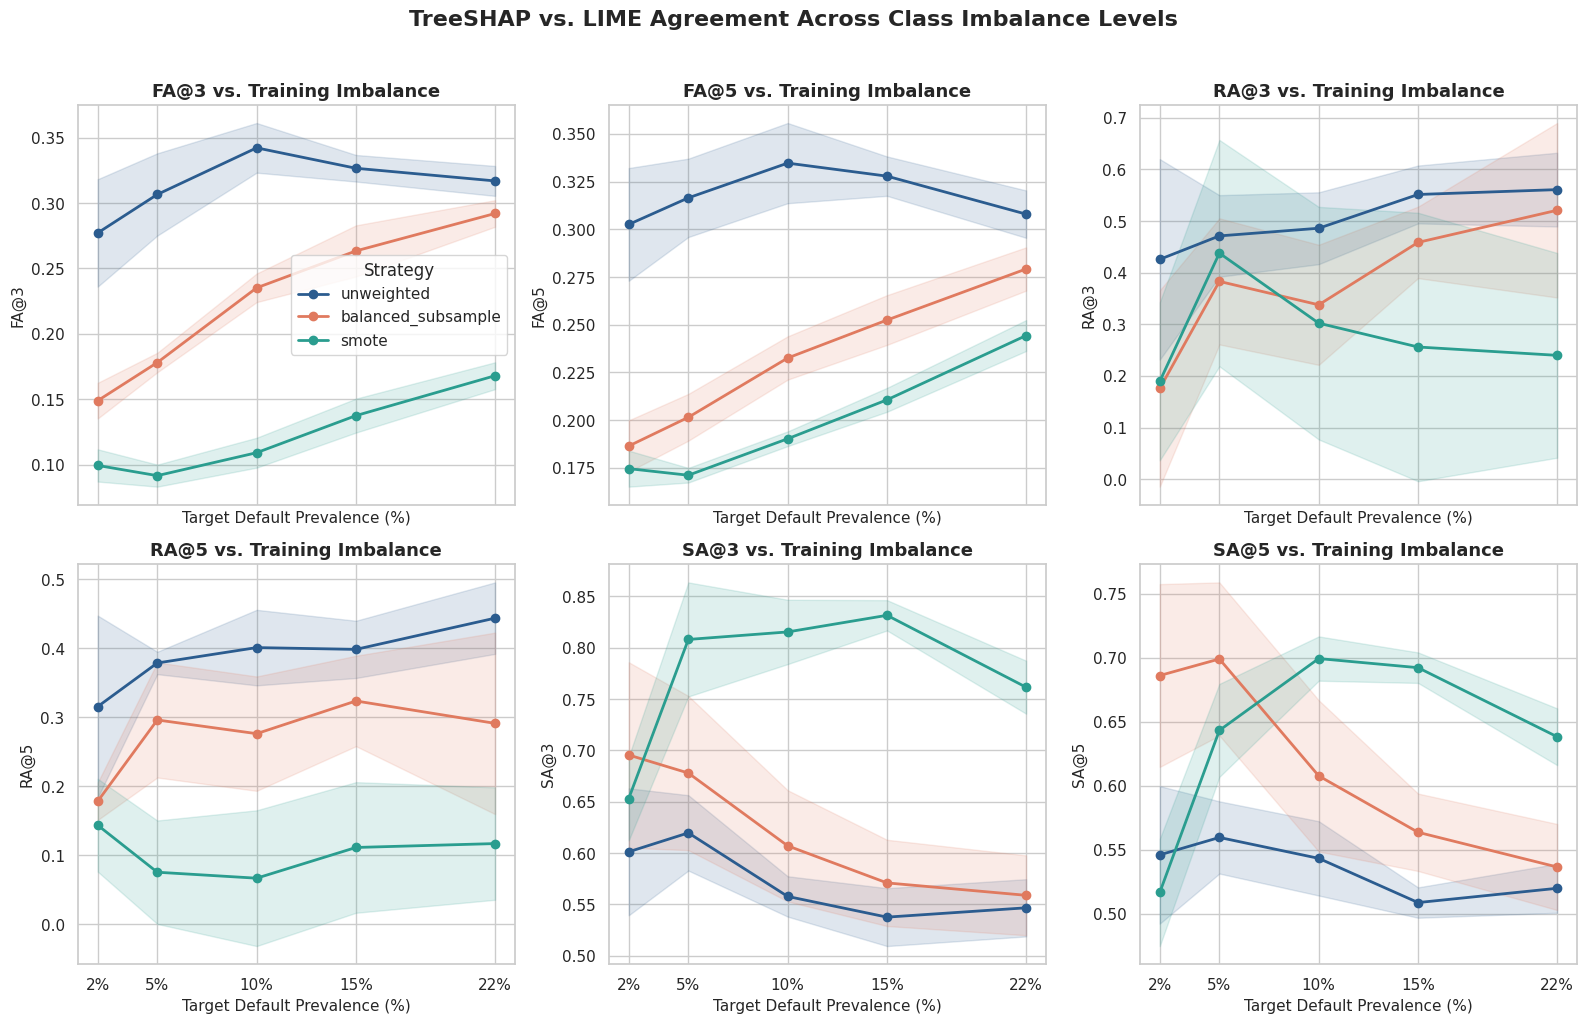

In [12]:
# Cell 7: Disagreement Metrics vs. Training Prevalence
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set publication style
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# Load metrics
metrics_df = pd.read_csv("xai_disagreement_metrics_gpu_full.csv")

# Filter agreement metrics
agreement_metrics = ["FA@3", "FA@5", "RA@3", "RA@5", "SA@3", "SA@5"]
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True)
axes = axes.flatten()

strategies = ["unweighted", "balanced_subsample", "smote"]
colors = {"unweighted": "#2b5c8f", "balanced_subsample": "#e07a5f", "smote": "#2a9d8f"}

for idx, metric_name in enumerate(agreement_metrics):
    ax = axes[idx]
    subset = metrics_df[metrics_df["metric"] == metric_name]

    # Aggregate split-level means
    split_means = (
        subset.groupby(["split", "target_prevalence", "strategy"])["value"]
        .mean()
        .reset_index()
    )

    for strategy in strategies:
        s_data = split_means[split_means["strategy"] == strategy]
        if s_data.empty:
            continue

        summary_stats = (
            s_data.groupby("target_prevalence")["value"]
            .agg(mean="mean", std="std", count="count")
            .reset_index()
        )
        summary_stats["ci"] = 1.96 * (summary_stats["std"] / np.sqrt(summary_stats["count"]))
        summary_stats = summary_stats.sort_values("target_prevalence")

        x_vals = summary_stats["target_prevalence"] * 100
        y_vals = summary_stats["mean"]
        ci_vals = summary_stats["ci"]

        ax.plot(x_vals, y_vals, marker="o", linewidth=2, label=strategy, color=colors[strategy])
        ax.fill_between(x_vals, y_vals - ci_vals, y_vals + ci_vals, color=colors[strategy], alpha=0.15)

    ax.set_title(f"{metric_name} vs. Training Imbalance", fontsize=13, fontweight="bold")
    ax.set_xlabel("Target Default Prevalence (%)", fontsize=11)
    ax.set_ylabel(metric_name, fontsize=11)
    ax.set_xticks([2, 5, 10, 15, 22])
    ax.set_xticklabels(["2%", "5%", "10%", "15%", "22%"])
    if idx == 0:
        ax.legend(title="Strategy", frameon=True)

plt.suptitle("TreeSHAP vs. LIME Agreement Across Class Imbalance Levels", fontsize=16, fontweight="bold", y=1.02)
plt.savefig("xai_agreement_metrics_full.png", dpi=300, bbox_inches="tight")
plt.show()

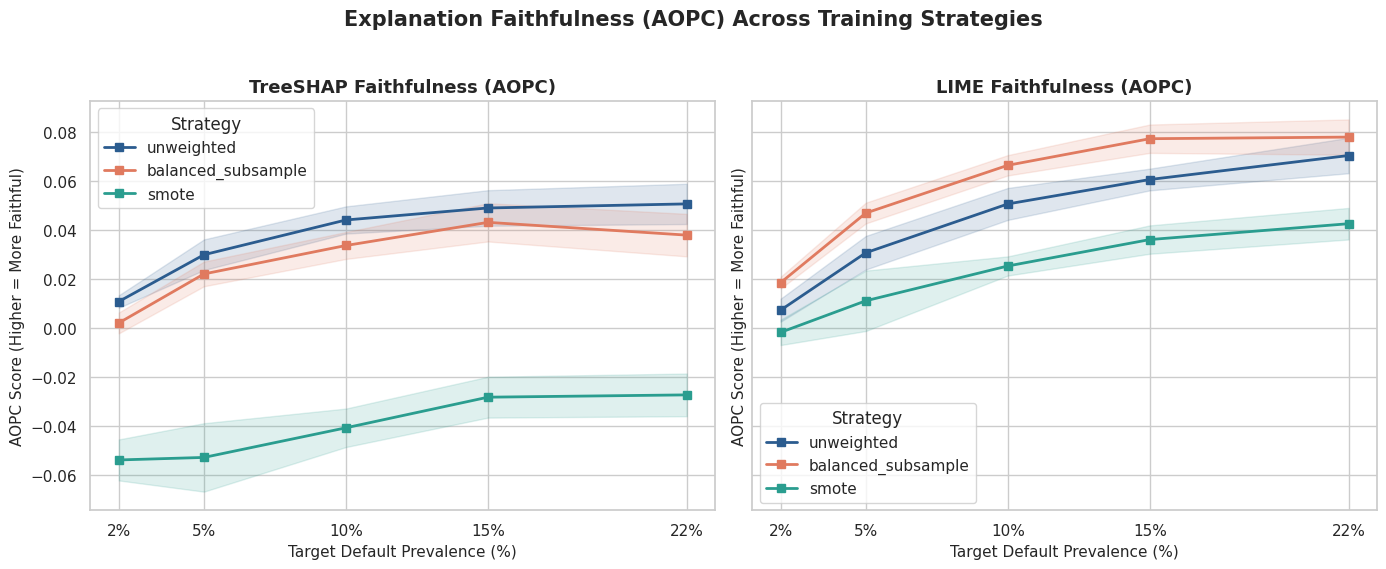

In [13]:
# Cell 8: Explanation Faithfulness (AOPC) Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

aopc_df = metrics_df[metrics_df["metric"].isin(["AOPC_TreeSHAP", "AOPC_LIME"])]
split_aopc = (
    aopc_df.groupby(["split", "target_prevalence", "strategy", "metric"])["value"]
    .mean()
    .reset_index()
)

explainer_titles = {"AOPC_TreeSHAP": "TreeSHAP Faithfulness (AOPC)", "AOPC_LIME": "LIME Faithfulness (AOPC)"}

for idx, explainer_metric in enumerate(["AOPC_TreeSHAP", "AOPC_LIME"]):
    ax = axes[idx]

    for strategy in strategies:
        s_data = split_aopc[(split_aopc["strategy"] == strategy) & (split_aopc["metric"] == explainer_metric)]
        summary_stats = (
            s_data.groupby("target_prevalence")["value"]
            .agg(mean="mean", std="std", count="count")
            .reset_index()
            .sort_values("target_prevalence")
        )
        summary_stats["ci"] = 1.96 * (summary_stats["std"] / np.sqrt(summary_stats["count"]))

        x_vals = summary_stats["target_prevalence"] * 100
        y_vals = summary_stats["mean"]
        ci_vals = summary_stats["ci"]

        ax.plot(x_vals, y_vals, marker="s", linewidth=2, label=strategy, color=colors[strategy])
        ax.fill_between(x_vals, y_vals - ci_vals, y_vals + ci_vals, color=colors[strategy], alpha=0.15)

    ax.set_title(explainer_titles[explainer_metric], fontsize=13, fontweight="bold")
    ax.set_xlabel("Target Default Prevalence (%)", fontsize=11)
    ax.set_ylabel("AOPC Score (Higher = More Faithful)", fontsize=11)
    ax.set_xticks([2, 5, 10, 15, 22])
    ax.set_xticklabels(["2%", "5%", "10%", "15%", "22%"])
    ax.legend(title="Strategy", frameon=True)

plt.suptitle("Explanation Faithfulness (AOPC) Across Training Strategies", fontsize=15, fontweight="bold", y=1.03)
plt.savefig("aopc_faithfulness_comparison_full.png", dpi=300, bbox_inches="tight")
plt.show()

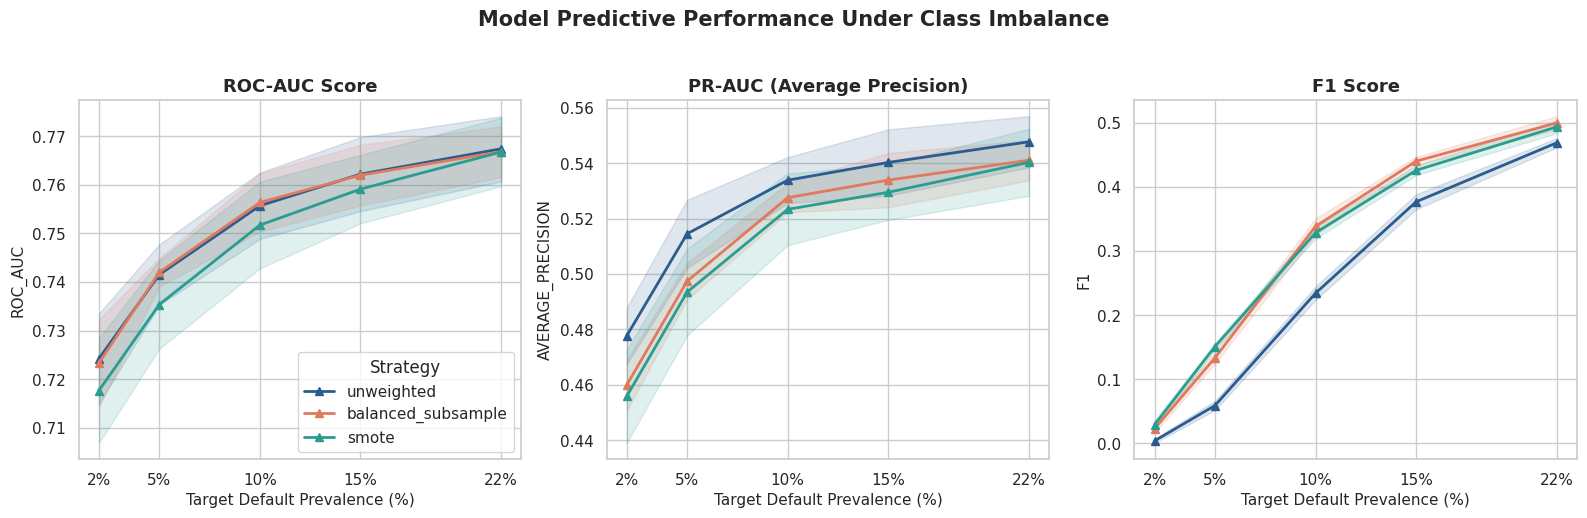

In [14]:
# Cell 9: Predictive Performance Across Imbalance Levels
models_df = pd.read_csv("predictive_metrics_gpu_full.csv")
models_clean = models_df[models_df["strategy"] != "dummy_prior"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
eval_metrics = [("roc_auc", "ROC-AUC Score"), ("average_precision", "PR-AUC (Average Precision)"), ("f1", "F1 Score")]

for idx, (metric_col, title_name) in enumerate(eval_metrics):
    ax = axes[idx]

    for strategy in strategies:
        s_data = models_clean[models_clean["strategy"] == strategy]
        summary_stats = (
            s_data.groupby("target_prevalence")[metric_col]
            .agg(mean="mean", std="std", count="count")
            .reset_index()
            .sort_values("target_prevalence")
        )
        summary_stats["ci"] = 1.96 * (summary_stats["std"] / np.sqrt(summary_stats["count"]))

        x_vals = summary_stats["target_prevalence"] * 100
        y_vals = summary_stats["mean"]
        ci_vals = summary_stats["ci"]

        ax.plot(x_vals, y_vals, marker="^", linewidth=2, label=strategy, color=colors[strategy])
        ax.fill_between(x_vals, y_vals - ci_vals, y_vals + ci_vals, color=colors[strategy], alpha=0.15)

    ax.set_title(title_name, fontsize=13, fontweight="bold")
    ax.set_xlabel("Target Default Prevalence (%)", fontsize=11)
    ax.set_ylabel(metric_col.upper(), fontsize=11)
    ax.set_xticks([2, 5, 10, 15, 22])
    ax.set_xticklabels(["2%", "5%", "10%", "15%", "22%"])
    if idx == 0:
        ax.legend(title="Strategy", frameon=True)

plt.suptitle("Model Predictive Performance Under Class Imbalance", fontsize=15, fontweight="bold", y=1.03)
plt.savefig("predictive_performance_curves_full.png", dpi=300, bbox_inches="tight")
plt.show()